# 02 · Modelo de pronóstico — Favorita Demand Forecast

Este notebook **explica** los resultados de `python -m src.model` (no reentrena): métricas de backtest frente a los baselines, error por familia, importancia de variables (gain y SHAP), un ejemplo de pronóstico y la recomendación de inventario ilustrativa.

**Configuración**
- Objetivo: `log1p(sales)` por fecha–tienda–familia (1,782 series), con un único modelo global LightGBM.
- Horizonte: 16 días. Todas las variables que miran ventas pasadas usan desfases ≥ 16 días.
- Validación: 3 cortes de 16 días al final del periodo (29-jun a 15-ago-2017). En cada corte el *early stopping* usa los 16 días previos al corte, nunca la ventana evaluada.
- Baselines: naive estacional (mismo día de la semana de la última semana observada) y promedio móvil de 14 días.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
from src import config, features, inventory, model as M
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
ACC, GRY, BLU = "#B4532A", "#8A8478", "#2F5D7C"
pd.set_option("display.float_format", "{:,.4f}".format)
con = duckdb.connect(str(config.DUCKDB_PATH), read_only=True)
info = json.loads((config.DATA_PROCESSED / "model_info.json").read_text(encoding="utf-8"))
preds = pd.read_parquet(config.DATA_PROCESSED / "backtest_predictions.parquet")
fam = con.execute("SELECT family_id, family FROM gold.dim_family").df()
{k: info[k] for k in ["train_start", "last_train_date", "best_iterations", "final_rounds", "n_series", "n_train_rows_final", "n_features"]}

{'train_start': '2015-01-01',
 'last_train_date': '2017-08-15',
 'best_iterations': [478, 513, 103],
 'final_rounds': 382,
 'n_series': 1782,
 'n_train_rows_final': 1703592,
 'n_features': 37}

## 1. Modelo vs. baselines

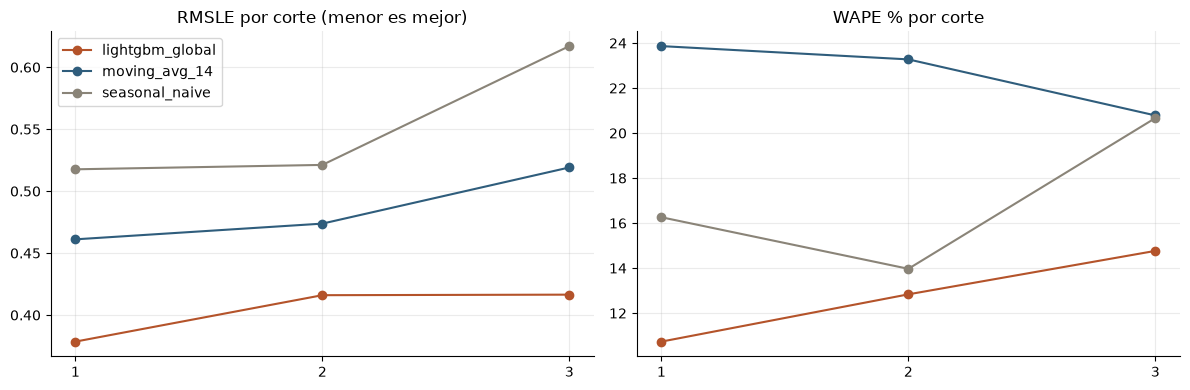

Mejora vs naive estacional: RMSLE 26.9%, WAPE 24.7%


,rmsle,wape,bias
model_name,,,
lightgbm_global,0.4037,0.1278,-0.0248
moving_avg_14,0.4847,0.2264,-0.0059
seasonal_naive,0.5519,0.1696,-0.0310


In [2]:
met = con.execute("""SELECT model_name, fold, cutoff_date, rmsle, wape, bias FROM gold.fact_backtest_metrics
                      WHERE segment = 'ALL' ORDER BY fold, model_name""").df()
res = met.groupby("model_name")[["rmsle", "wape", "bias"]].mean().sort_values("rmsle")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cols = {"lightgbm_global": ACC, "seasonal_naive": GRY, "moving_avg_14": BLU}
for m, g in met.groupby("model_name"):
    ax[0].plot(g.fold, g.rmsle, marker="o", color=cols[m], label=m); ax[1].plot(g.fold, g.wape * 100, marker="o", color=cols[m], label=m)
ax[0].set_title("RMSLE por corte (menor es mejor)"); ax[1].set_title("WAPE % por corte"); ax[0].set_xticks([1, 2, 3]); ax[1].set_xticks([1, 2, 3]); ax[0].legend()
plt.tight_layout(); plt.show()
mejora = 1 - res.loc["lightgbm_global"] / res.loc["seasonal_naive"]
print(f"Mejora vs naive estacional: RMSLE {mejora.rmsle:.1%}, WAPE {mejora.wape:.1%}")
res

**Conclusión.** El modelo global baja el RMSLE de 0.552 (naive estacional) a 0.404, una mejora de 27%, y el WAPE de 17.0% a 12.8% (−25%). Gana en los tres cortes. El promedio móvil de 14 días tiene mejor RMSLE que el naive (0.485), pero peor WAPE (22.6%) porque ignora el patrón semanal. El sesgo del modelo es −2.5%: subpronostica levemente, algo a vigilar porque un sesgo negativo se traduce en quiebres de stock.

## 2. Pronóstico agregado vs. real en los cortes

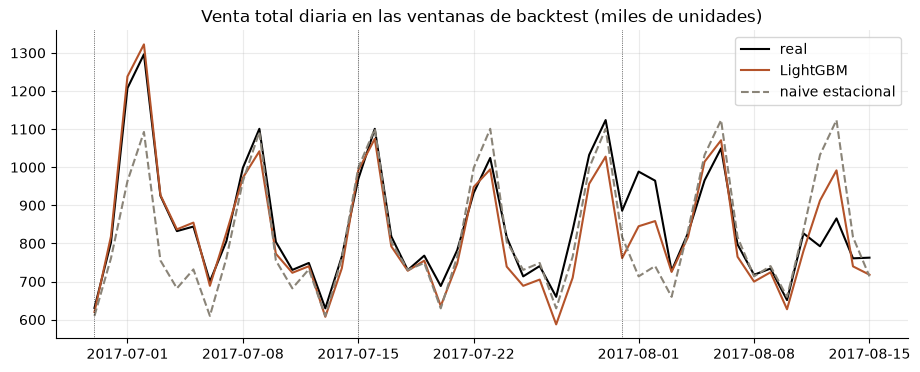

Error absoluto del total diario de la cadena: 4.8%


In [3]:
agg = preds.groupby("date")[["sales", "lightgbm_global", "seasonal_naive"]].sum() / 1e3
fig, ax = plt.subplots()
ax.plot(agg.index, agg.sales, color="k", lw=1.5, label="real")
ax.plot(agg.index, agg.lightgbm_global, color=ACC, label="LightGBM")
ax.plot(agg.index, agg.seasonal_naive, color=GRY, ls="--", label="naive estacional")
for ini, _ in M.fold_windows(): ax.axvline(ini, color="k", lw=.5, ls=":")
ax.set_title("Venta total diaria en las ventanas de backtest (miles de unidades)"); ax.legend(); plt.show()
err_tot = (agg.lightgbm_global - agg.sales).abs().sum() / agg.sales.sum()
print(f"Error absoluto del total diario de la cadena: {err_tot:.1%}")

**Conclusión.** A nivel cadena, el total diario se equivoca 4.8% en promedio: al sumar, los errores de tiendas y familias se compensan. El WAPE de 12.8% es por tienda–familia–día, que es el nivel en que se decide la reposición.

## 3. Error por familia

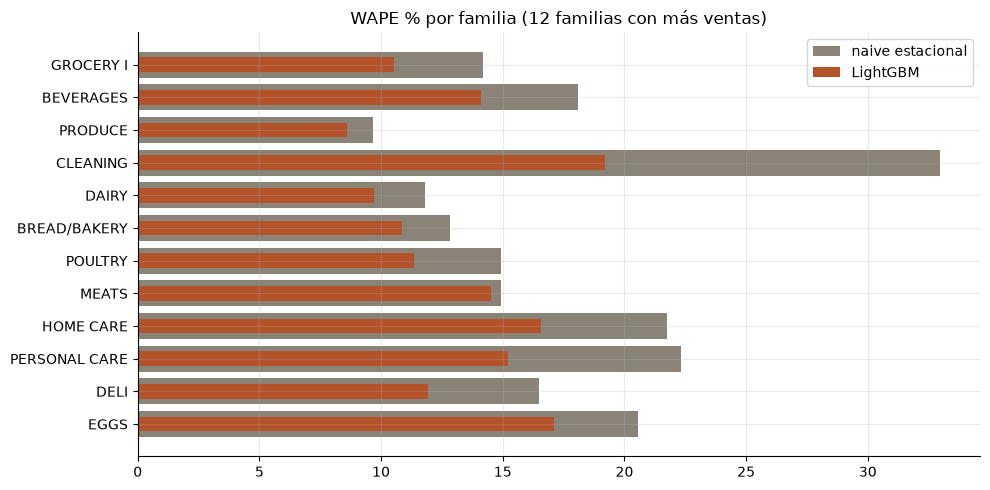

LightGBM tiene menor WAPE que el naive en 32 de 33 familias


,lightgbm_global,moving_avg_14,seasonal_naive,ventas_backtest
family,,,,
GROCERY I,0.1050,0.1940,0.1420,"12,002,769.1240"
BEVERAGES,0.1410,0.2290,0.1810,"9,320,572.0000"
PRODUCE,0.0860,0.2150,0.0970,"6,066,630.4620"
CLEANING,0.1920,0.2940,0.3300,"3,399,532.0000"
DAIRY,0.0970,0.1900,0.1180,"2,259,900.0000"
BREAD/BAKERY,0.1090,0.1810,0.1280,"1,418,026.6780"
POULTRY,0.1130,0.2450,0.1490,"1,018,693.0300"
MEATS,0.1450,0.2620,0.1490,"990,074.3480"
HOME CARE,0.1660,0.2640,0.2180,"824,459.0000"


In [4]:
mf = con.execute("""SELECT segment AS family, model_name, avg(wape) AS wape, avg(rmsle) AS rmsle
                     FROM gold.fact_backtest_metrics WHERE segment <> 'ALL' GROUP BY ALL""").df()
w = mf.pivot(index="family", columns="model_name", values="wape")
vol = preds.merge(fam, on="family_id").groupby("family").sales.sum().rename("ventas_backtest")
w = w.join(vol).sort_values("ventas_backtest", ascending=False)
top = w.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.index, top.seasonal_naive * 100, color=GRY, label="naive estacional")
ax.barh(top.index, top.lightgbm_global * 100, color=ACC, height=.45, label="LightGBM")
ax.set_title("WAPE % por familia (12 familias con más ventas)"); ax.legend(); plt.tight_layout(); plt.show()
gana = (w.lightgbm_global < w.seasonal_naive).sum()
print(f"LightGBM tiene menor WAPE que el naive en {gana} de {len(w)} familias")
w.round(3)

**Conclusión.** LightGBM mejora al naive en 32 de 33 familias. En las cinco familias más grandes el WAPE va de 8.6% (PRODUCE) a 19.2% (CLEANING), con GROCERY I en 10.5%. La excepción es BOOKS, que tiene ventas en cero el 97% de los días: cualquier venta esporádica dispara el WAPE y no tiene sentido pronosticarla con este modelo. Las familias de baja rotación, como GROCERY II, HOME AND KITCHEN o LIQUOR,WINE,BEER, quedan con errores de 26% a 42%.

## 4. Importancia de variables

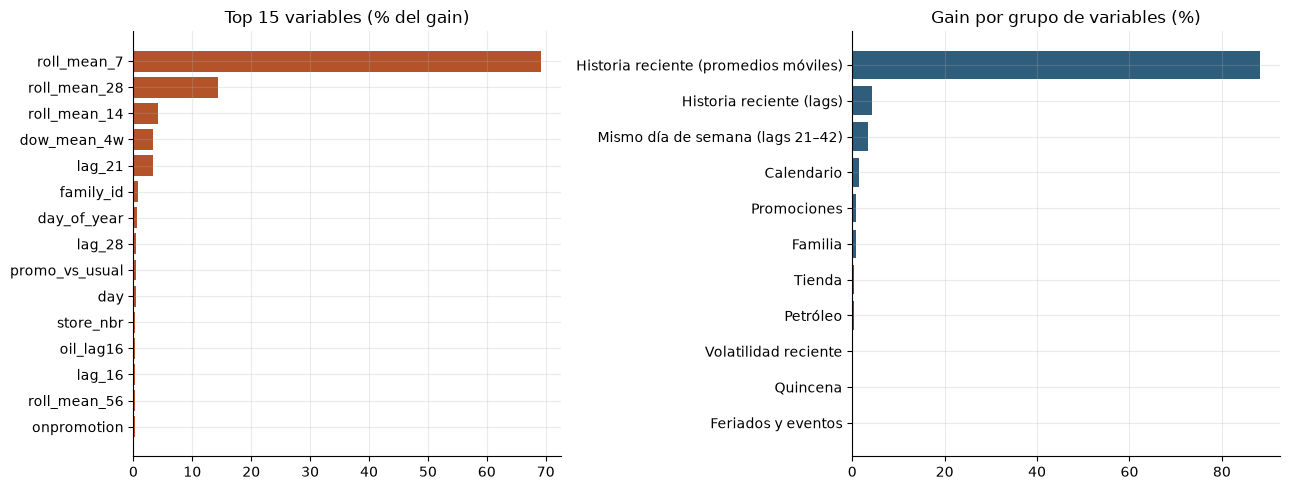

grupo
Historia reciente (promedios móviles)    88.2%
Historia reciente (lags)                  4.4%
Mismo día de semana (lags 21–42)          3.3%
Calendario                                1.4%
Promociones                               0.8%
Familia                                   0.7%
Tienda                                    0.4%
Petróleo                                  0.3%
Volatilidad reciente                      0.2%
Quincena                                  0.1%
Feriados y eventos                        0.0%
Name: gain_share, dtype: str

In [5]:
imp = pd.read_parquet(config.DATA_PROCESSED / "feature_importance.parquet")
grupos = {"roll_mean": "Historia reciente (promedios móviles)", "lag_": "Historia reciente (lags)", "dow_mean": "Mismo día de semana (lags 21–42)",
          "roll_std": "Volatilidad reciente", "zero_share": "Volatilidad reciente", "promo": "Promociones", "onpromotion": "Promociones",
          "oil": "Petróleo", "holiday": "Feriados y eventos", "event": "Feriados y eventos", "work_day": "Feriados y eventos", "christmas": "Feriados y eventos",
          "payday": "Quincena", "store_nbr": "Tienda", "store_type": "Tienda", "cluster": "Tienda", "city": "Tienda", "state": "Tienda",
          "family_id": "Familia", "day": "Calendario", "month": "Calendario", "week": "Calendario"}
imp["grupo"] = imp.feature.map(lambda f: next((v for k, v in grupos.items() if k in f), "Otros"))
g = imp.groupby("grupo").gain_share.sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
t15 = imp.head(15).iloc[::-1]; ax[0].barh(t15.feature, t15.gain_share * 100, color=ACC); ax[0].set_title("Top 15 variables (% del gain)")
ax[1].barh(g.index, g.values * 100, color=BLU); ax[1].set_title("Gain por grupo de variables (%)")
plt.tight_layout(); plt.show()
g.sort_values(ascending=False).map(lambda v: f"{v:.1%}")

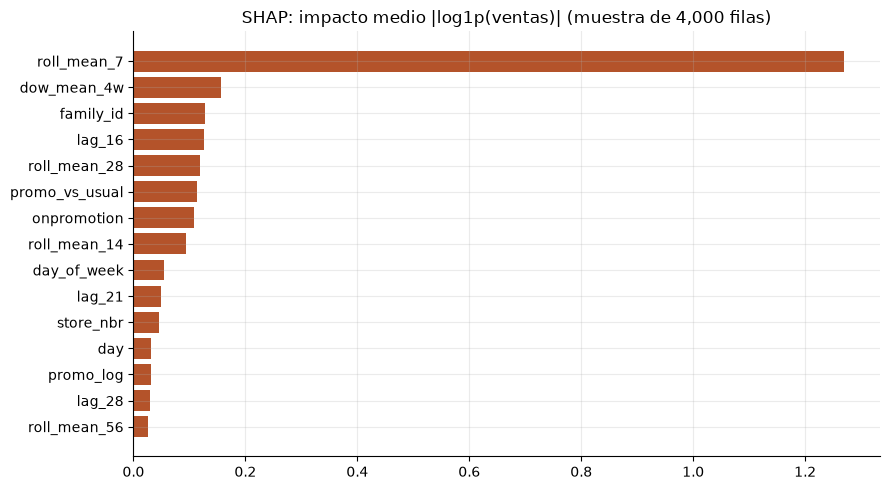

roll_mean_7      1.2700
dow_mean_4w      0.1560
family_id        0.1270
lag_16           0.1250
roll_mean_28     0.1180
promo_vs_usual   0.1130
onpromotion      0.1090
roll_mean_14     0.0940


promo_vs_usual > 0 (más promos que lo habitual)    +54.8% en ventas (aprox.)
domingo vs resto (day_of_week)                     +10.8% en ventas (aprox.)
días 1–3 tras el pago (days_since_payday)           +1.8% en ventas (aprox.)
dtype: str

In [6]:
# SHAP sobre una muestra de la última ventana de backtest (cabe en memoria)
import shap
booster = lgb.Booster(model_file=str(config.MODELS_DIR / f"{M.MODEL_NAME}_{M.MODEL_VERSION}.txt"))
panel = features.add_features(features.load_panel(con))
ini, fin = M.fold_windows()[-1]
muestra = panel[(panel.date >= ini) & (panel.date <= fin) & (panel.sales > 0)].sample(4000, random_state=42)
sv = shap.TreeExplainer(booster).shap_values(muestra[features.FEATURES])
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=features.FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5)); s = shap_imp.head(15).iloc[::-1]
ax.barh(s.index, s.values, color=ACC); ax.set_title("SHAP: impacto medio |log1p(ventas)| (muestra de 4,000 filas)"); plt.tight_layout(); plt.show()
print(shap_imp.head(8).round(3).to_string())
# Dirección de efectos de calendario y promo
def efecto(col, cond):
    i = features.FEATURES.index(col); m = cond(muestra[col]).to_numpy()
    return sv[m, i].mean() - sv[~m, i].mean()
direccion = {
    "promo_vs_usual > 0 (más promos que lo habitual)": efecto("promo_vs_usual", lambda s: s > 0),
    "domingo vs resto (day_of_week)": efecto("day_of_week", lambda s: s == 6),
    "días 1–3 tras el pago (days_since_payday)": efecto("days_since_payday", lambda s: s.between(1, 3)),
}
pd.Series(direccion).map(lambda v: f"{np.expm1(v):+.1%} en ventas (aprox.)")

**Conclusión (para negocio).** Para saber cuánto venderá una tienda en las próximas semanas, lo que más pesa es cuánto vendió en las últimas: el 88% del *gain* viene de los promedios móviles de log-ventas, sobre todo el de 7 días que termina 16 días antes del día pronosticado. Les siguen los lags y el promedio del mismo día de la semana (8% entre ambos).

Promociones, calendario y quincena aportan poco *gain* porque ajustan ese nivel en pocas filas, pero SHAP muestra que el modelo los usa en la dirección esperada:
- Cuando una serie tiene más productos en promoción de lo habitual, el modelo sube el pronóstico alrededor de 55%. Es una asociación aprendida, no un efecto causal: Favorita probablemente promociona lo que espera vender más.
- El domingo, alrededor de 11% más.
- Los días 1–3 tras el pago, alrededor de 2%; parte del efecto quincena puede estar absorbida por la variable `day`.

Los feriados tienen *gain* casi nulo: con dos años y medio de entrenamiento hay pocos feriados de cada tipo, y el único feriado nacional dentro de las ventanas de validación es el traslado del 11-ago-2017 (hay algunos locales, como la Fundación de Guayaquil). El petróleo aporta 0.3%, en línea con el EDA.

## 5. Ejemplo: una serie con su pronóstico

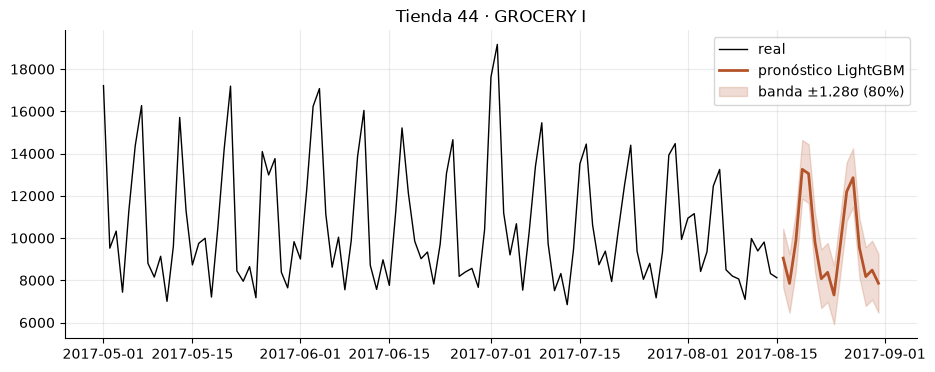

σ del error diario en backtest: 1,086 unidades; pronóstico 16 días: 155,455 unidades


In [7]:
ej_store, ej_fam = 44, int(fam.loc[fam.family == "GROCERY I", "family_id"].iloc[0])
hist = con.execute(f"""SELECT date, sales FROM gold.fact_sales WHERE store_nbr = {ej_store} AND family_id = {ej_fam}
                       AND date >= '2017-05-01' ORDER BY date""").df()
fc = con.execute(f"""SELECT date, model_name, forecast FROM gold.fact_forecast WHERE store_nbr = {ej_store}
                     AND family_id = {ej_fam} ORDER BY date""").df().pivot(index="date", columns="model_name", values="forecast")
sig = pd.read_parquet(config.DATA_PROCESSED / "residual_sigma.parquet").query("store_nbr == @ej_store and family_id == @ej_fam").sigma_daily.iloc[0]
fig, ax = plt.subplots()
ax.plot(pd.to_datetime(hist.date), hist.sales, color="k", lw=1, label="real")
x = pd.to_datetime(fc.index)
ax.plot(x, fc.lightgbm_global, color=ACC, lw=2, label="pronóstico LightGBM")
ax.fill_between(x, (fc.lightgbm_global - 1.28 * sig).clip(lower=0), fc.lightgbm_global + 1.28 * sig, color=ACC, alpha=.2, label="banda ±1.28σ (80%)")
ax.set_title(f"Tienda {ej_store} · GROCERY I"); ax.legend(); plt.show()
print(f"σ del error diario en backtest: {sig:,.0f} unidades; pronóstico 16 días: {fc.lightgbm_global.sum():,.0f} unidades")

## 6. Recomendación de inventario (ilustrativa)

In [8]:
L = 7
fc7 = fc.lightgbm_global.iloc[:L].sum()
tabla = pd.DataFrame([{"nivel_servicio": f"{nl:.0%}", "pronostico_7d": fc7,
                       "stock_seguridad": inventory.safety_stock(sig, L, nl),
                       "stock_objetivo": inventory.target_stock(fc7, sig, L, nl)} for nl in (0.90, 0.95, 0.98)])
tabla.style.format({"pronostico_7d": "{:,.0f}", "stock_seguridad": "{:,.0f}", "stock_objetivo": "{:,.0f}"})

,nivel_servicio,pronostico_7d,stock_seguridad,stock_objetivo
0,90%,"70,965","3,683","74,648"
1,95%,"70,965","4,728","75,692"
2,98%,"70,965","5,902","76,867"


**Cómo leerlo.** Para un tiempo de reposición de 7 días, el stock objetivo es el pronóstico de esos 7 días más un colchón proporcional al error histórico del modelo en esa serie (σ × √7) y al nivel de servicio. Subir de 90% a 98% encarece el colchón en un 60% (z pasa de 1.28 a 2.05).

> ⚠️ Es una **heurística didáctica**: supone errores diarios independientes y normales, no considera stock en tránsito, vida útil, mínimos de pedido ni costos. **No es la política de inventario de Favorita.**

## 7. Limitaciones

- **Ventanas de validación cortas y de verano** (29-jun a 15-ago-2017): no hay diciembre ni feriados grandes. El error en Navidad probablemente sea mayor.
- **Shocks únicos** como el terremoto de 2016 no se pueden aprender para el futuro.
- **Promociones**: el modelo conoce `onpromotion` del día porque está en test.csv; en la operación real eso exige tener el plan de promociones cargado con anticipación.
- **Unidades, no dólares**: el dataset no trae precios, así que WAPE y stock están en unidades (o kilos en algunas familias).
- **Series esporádicas** (BOOKS, BABY CARE, HOME APPLIANCES): un modelo de demanda intermitente (Croston/TSB) sería más apropiado.
- **Inventario**: la fórmula es didáctica y no reemplaza una política real (lead times reales, vida útil, mínimos, costos).

In [9]:
con.close()